## Perguntas escolhidas:

- Existe correlação entre Feature Streams e Total Streams - "features" realmente impulsionam a carreira?
- Artistas de língua não-inglesa (Espanhol, Português, Coreano) competem em volume de streams com os de língua inglesa, ou há uma disparidade grande?
- A proporção de artistas solo varia entre as décadas de estreia?
- A proporção de artistas solo varia entre os sexos?


## Setup de Bibliotecas e Dados

In [1]:
%pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [3]:
# O dataset já está salvo localmente em data/raw; não é necessário instalar nem acessar Kaggle.

In [4]:
from pathlib import Path

NOME_DATASET = "Spotify Streaming Performance Dataset.csv"

# Funciona tanto com o diretório atual na raiz do projeto quanto em notebooks/.
raiz_projeto = Path.cwd()
if not (raiz_projeto / "data" / "raw").is_dir():
    raiz_projeto = raiz_projeto.parent

caminho_csv = raiz_projeto / "data" / "raw" / NOME_DATASET
if not caminho_csv.is_file():
    raise FileNotFoundError(
        f"Dataset não encontrado em: {caminho_csv}. "
        "Confirme que o arquivo está em data/raw/."
    )

print("Usando dataset local:", caminho_csv)

Usando dataset local: c:\Users\brend\OneDrive\Documentos\AVD-2026-pratica-streamlit\AVD-20262-pratica-streamlit\data\raw\Spotify Streaming Performance Dataset.csv


In [5]:
# O caminho local do CSV foi definido na célula anterior.

In [6]:
import pandas as pd

df = pd.read_csv(caminho_csv, sep=",")
df.head()

,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams (in millions),Lead Streams (in millions),Feature Streams (in millions),Solo Streams (in millions),% of Solo Streams,Collaborative Streams (in millions),% of Collaborative Streams
0,Drake,Male,Canada,English,Hip-Hop,Solo,2006,137492.1,94851.1,42640.9,53323.9,38.783246,84168.2,61.216754
1,Taylor Swift,Female,United States,English,Pop,Solo,2006,127861.0,126177.3,1683.8,113421.5,88.706877,14439.5,11.293123
2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013,125899.8,82189.3,43710.5,48887.0,38.830086,77012.8,61.169914
3,The Weeknd,Male,Canada,English,R&B,Solo,2009,95703.2,77189.4,18513.8,51020.0,53.310652,44683.2,46.689348
4,Justin Bieber,Male,Canada,English,Pop,Solo,2009,78104.4,48316.2,29788.2,29638.3,37.947030,48466.1,62.052970


## 1. Princípio Estrutural



### Dimensão e Tipos de Dados

In [7]:
df.shape

(500, 14)

In [8]:
df.info() # possuí 500 linhas, e como fica evidente aqui, não tem valores não-nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Artist Name                          500 non-null    object 
 1   Sex                                  500 non-null    object 
 2   Country of Origin                    500 non-null    object 
 3   Primary Language                     500 non-null    object 
 4   Primary Genre                        500 non-null    object 
 5    Artist Type                         500 non-null    object 
 6   Debut Year                           500 non-null    int64  
 7   Total Streams (in millions)          500 non-null    float64
 8   Lead Streams (in millions)           500 non-null    float64
 9   Feature Streams (in millions)        500 non-null    float64
 10  Solo Streams (in millions)           500 non-null    float64
 11  % of Solo Streams               

In [9]:
df.describe() # traz um resumo estatístico dos dados
# apesar de possuir campos com 0, como solo streams, não indica um campo nulo, os dados foram tratados e inseridos, diferente da presença de NaN
# assim, só indica que um artísta pode não ter recebido nenhum stream como artista solo.

,Debut Year,Total Streams (in millions),Lead Streams (in millions),Feature Streams (in millions),Solo Streams (in millions),% of Solo Streams,Collaborative Streams (in millions),% of Collaborative Streams
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,2005.346000,16817.610200,12141.734000,4681.289000,8324.397600,50.613084,8493.212600,49.386916
std,13.312578,14845.197632,11844.675186,5952.827762,9589.010168,33.762147,9612.491536,33.762147
min,1939.000000,6972.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2001.750000,8768.175000,6489.750000,696.500000,2519.775000,20.117951,2015.650000,16.860219
50%,2009.000000,11923.250000,8716.350000,3005.600000,6472.950000,47.062829,6592.250000,52.937171
75%,2014.000000,18020.050000,13456.900000,6093.350000,10115.550000,83.139781,11019.575000,79.882049
max,2023.000000,137492.100000,126177.300000,43710.500000,113421.500000,100.000000,84168.200000,100.000000


### Duplicadas

In [10]:
df.duplicated().sum() # resultado índica que não há linhas com dados duplicados

np.int64(0)

### Renomeando atributo ' Artist Type'

In [11]:
df = df.rename(columns={' Artist Type': 'Artist Type'}) # removendo o espaço extra para facilitar consultas futuras
df.head()

,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams (in millions),Lead Streams (in millions),Feature Streams (in millions),Solo Streams (in millions),% of Solo Streams,Collaborative Streams (in millions),% of Collaborative Streams
0,Drake,Male,Canada,English,Hip-Hop,Solo,2006,137492.1,94851.1,42640.9,53323.9,38.783246,84168.2,61.216754
1,Taylor Swift,Female,United States,English,Pop,Solo,2006,127861.0,126177.3,1683.8,113421.5,88.706877,14439.5,11.293123
2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013,125899.8,82189.3,43710.5,48887.0,38.830086,77012.8,61.169914
3,The Weeknd,Male,Canada,English,R&B,Solo,2009,95703.2,77189.4,18513.8,51020.0,53.310652,44683.2,46.689348
4,Justin Bieber,Male,Canada,English,Pop,Solo,2009,78104.4,48316.2,29788.2,29638.3,37.947030,48466.1,62.052970


## 2. Dados Faltantes

In [12]:
df.isna().sum() # Não há dados nulos em nenhuma das colunas

Artist Name                            0
Sex                                    0
Country of Origin                      0
Primary Language                       0
Primary Genre                          0
Artist Type                            0
Debut Year                             0
Total Streams (in millions)            0
Lead Streams (in millions)             0
Feature Streams (in millions)          0
Solo Streams (in millions)             0
% of Solo Streams                      0
Collaborative Streams (in millions)    0
% of Collaborative Streams             0
dtype: int64

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [13]:
VARS_QUANT = ["Debut Year", "Total Streams (in millions)", "Lead Streams (in millions)",
              "Feature Streams (in millions)", "Solo Streams (in millions)",
              "% of Solo Streams", "Collaborative Streams (in millions)",
              "% of Collaborative Streams"]


desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Debut Year,2005.35,2009.00,13.31,1939.00,2023.00,-1.78,3.45
Total Streams (in millions),16817.61,11923.25,14845.20,6972.00,137492.10,4.00,22.75
Lead Streams (in millions),12141.73,8716.35,11844.68,0.00,126177.30,4.17,26.71
Feature Streams (in millions),4681.29,3005.60,5952.83,0.00,43710.50,2.61,9.50
Solo Streams (in millions),8324.40,6472.95,9589.01,0.00,113421.50,4.16,32.17
% of Solo Streams,50.61,47.06,33.76,0.00,100.00,0.04,-1.40
Collaborative Streams (in millions),8493.21,6592.25,9612.49,0.00,84168.20,2.92,14.22
% of Collaborative Streams,49.39,52.94,33.76,0.00,100.00,-0.04,-1.40


Com essa análise, percebemos algumas coisas como:

coluna de skewness:
- Debut  Year possuí a única negativa entre os demais, significa então que possuí poucos valores *bem baixos*, impactando a média para baixo.
- o percentual de streams solo e colaborativos são os mais próximos, de uma distribuição simétrica (básicamente simétricos com só +0.4 e -0.4 de diferença, respectivamente)

coluna de kurtosis:
- A coluna de percentual de streams solo e a de streams collaborativos possuem os valores de curtose mais baixos (negativos), indicando assim uma distribuição mais "achatada", poucos outliers.
- A coluna solo streams (in millions) possui o valor mais alto de todos: 32.17, indicando assim, outliers frequentes/extremos

In [14]:
# as análises quantitativas dizem "quanto", mas não dizem "quem" ou "em que contexto"
VARS_QUALI = ["Sex", "Country of Origin", "Primary Language", "Primary Genre", "Artist Type"]

### Tabelas de frequência (contagem e índividual)
resumo_quali = pd.DataFrame({
    "n_categorias": df[VARS_QUALI].nunique(),
    "categoria_mais_frequente": df[VARS_QUALI].mode().iloc[0],
    "freq_mais_frequente": [df[col].value_counts().iloc[0] for col in VARS_QUALI],
})
resumo_quali["%_mais_frequente"] = (resumo_quali["freq_mais_frequente"] / len(df) * 100).round(2)
resumo_quali

,n_categorias,categoria_mais_frequente,freq_mais_frequente,%_mais_frequente
Sex,3,Male,390,78.0
Country of Origin,43,United States,265,53.0
Primary Language,11,English,340,68.0
Primary Genre,23,Hip-Hop,115,23.0
Artist Type,2,Solo,373,74.6


In [15]:
# distribuição completa índividual para ver os detalhes de cada uma das categorias
for col in VARS_QUALI:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')


--- Sex ---
Sex
Male      78.0%
Female    17.6%
Mixed      4.4%
Name: proportion, dtype: object

--- Country of Origin ---
Country of Origin
United States          53.0%
United Kingdom         11.0%
Mexico                  5.4%
Canada                  3.6%
Colombia                3.2%
Brazil                  3.0%
India                   2.6%
South Korea             2.2%
Argentina               1.8%
Australia               1.4%
Germany                 1.4%
Spain                   1.2%
Sweden                  1.0%
France                  1.0%
Ireland                 0.8%
Italy                   0.6%
Japan                   0.4%
Scotland                0.4%
Jamaica                 0.4%
Nigeria                 0.4%
Dominican Republic      0.4%
Norway                  0.4%
Netherlands             0.4%
Barbados                0.2%
Trinidad and Tobago     0.2%
Panama                  0.2%
Cuba                    0.2%
Morocco                 0.2%
New Zealand             0.2%
Senegal          

### Distribuições de dados




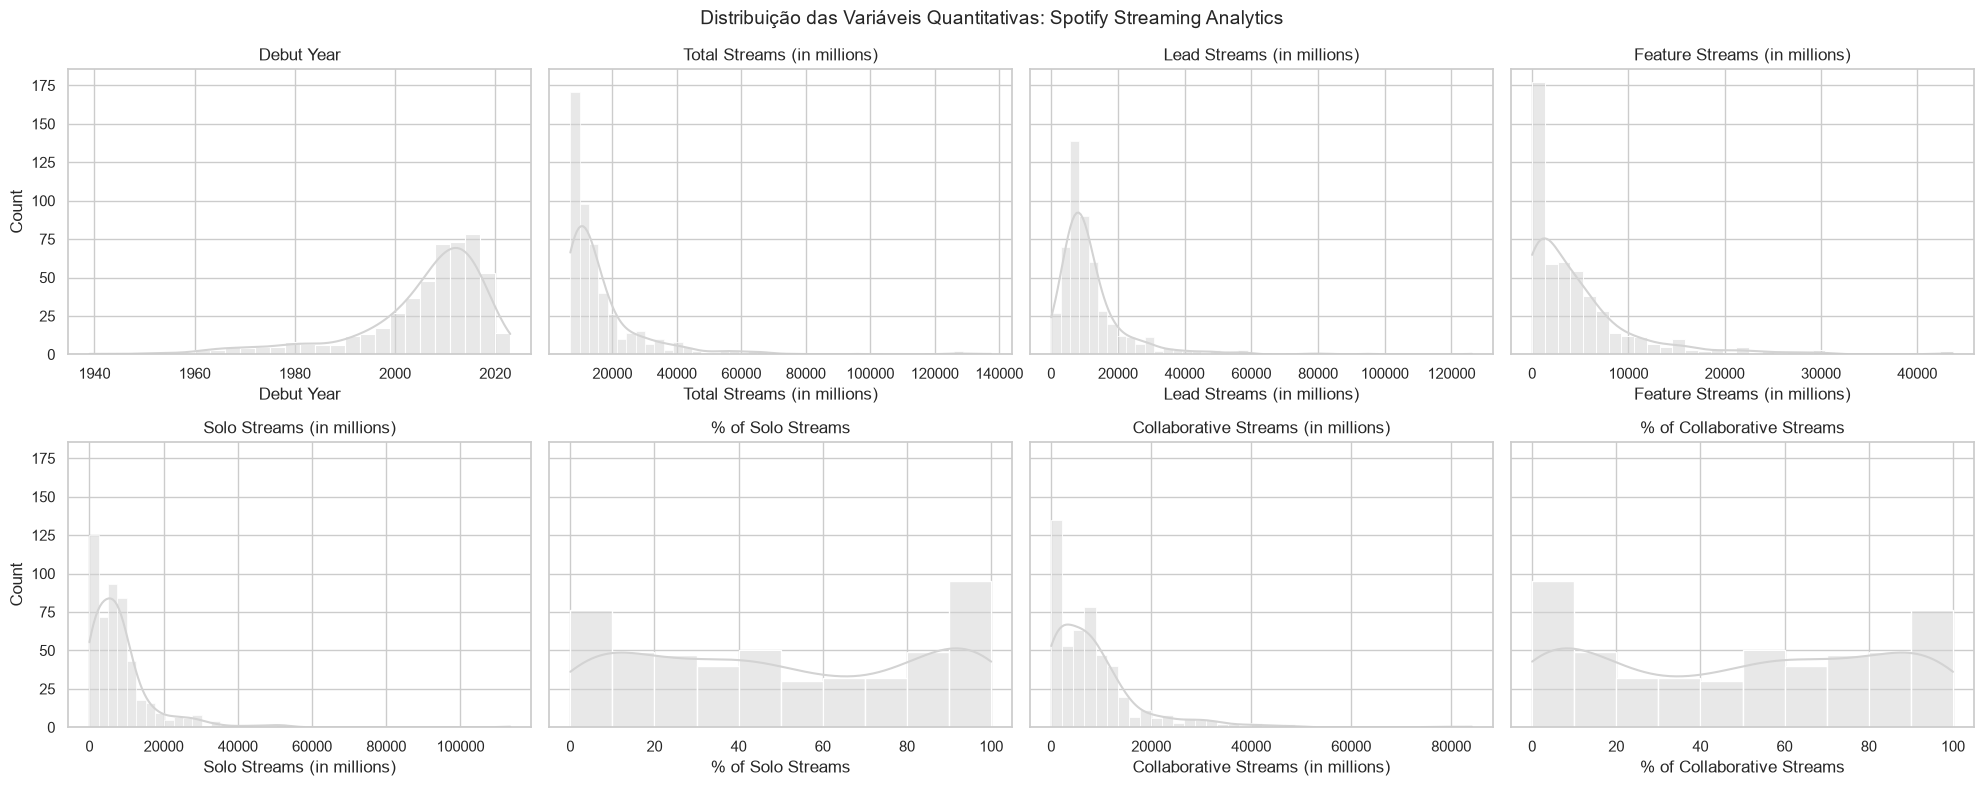

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Spotify Streaming Analytics", fontsize=14)
plt.tight_layout()
plt.show()

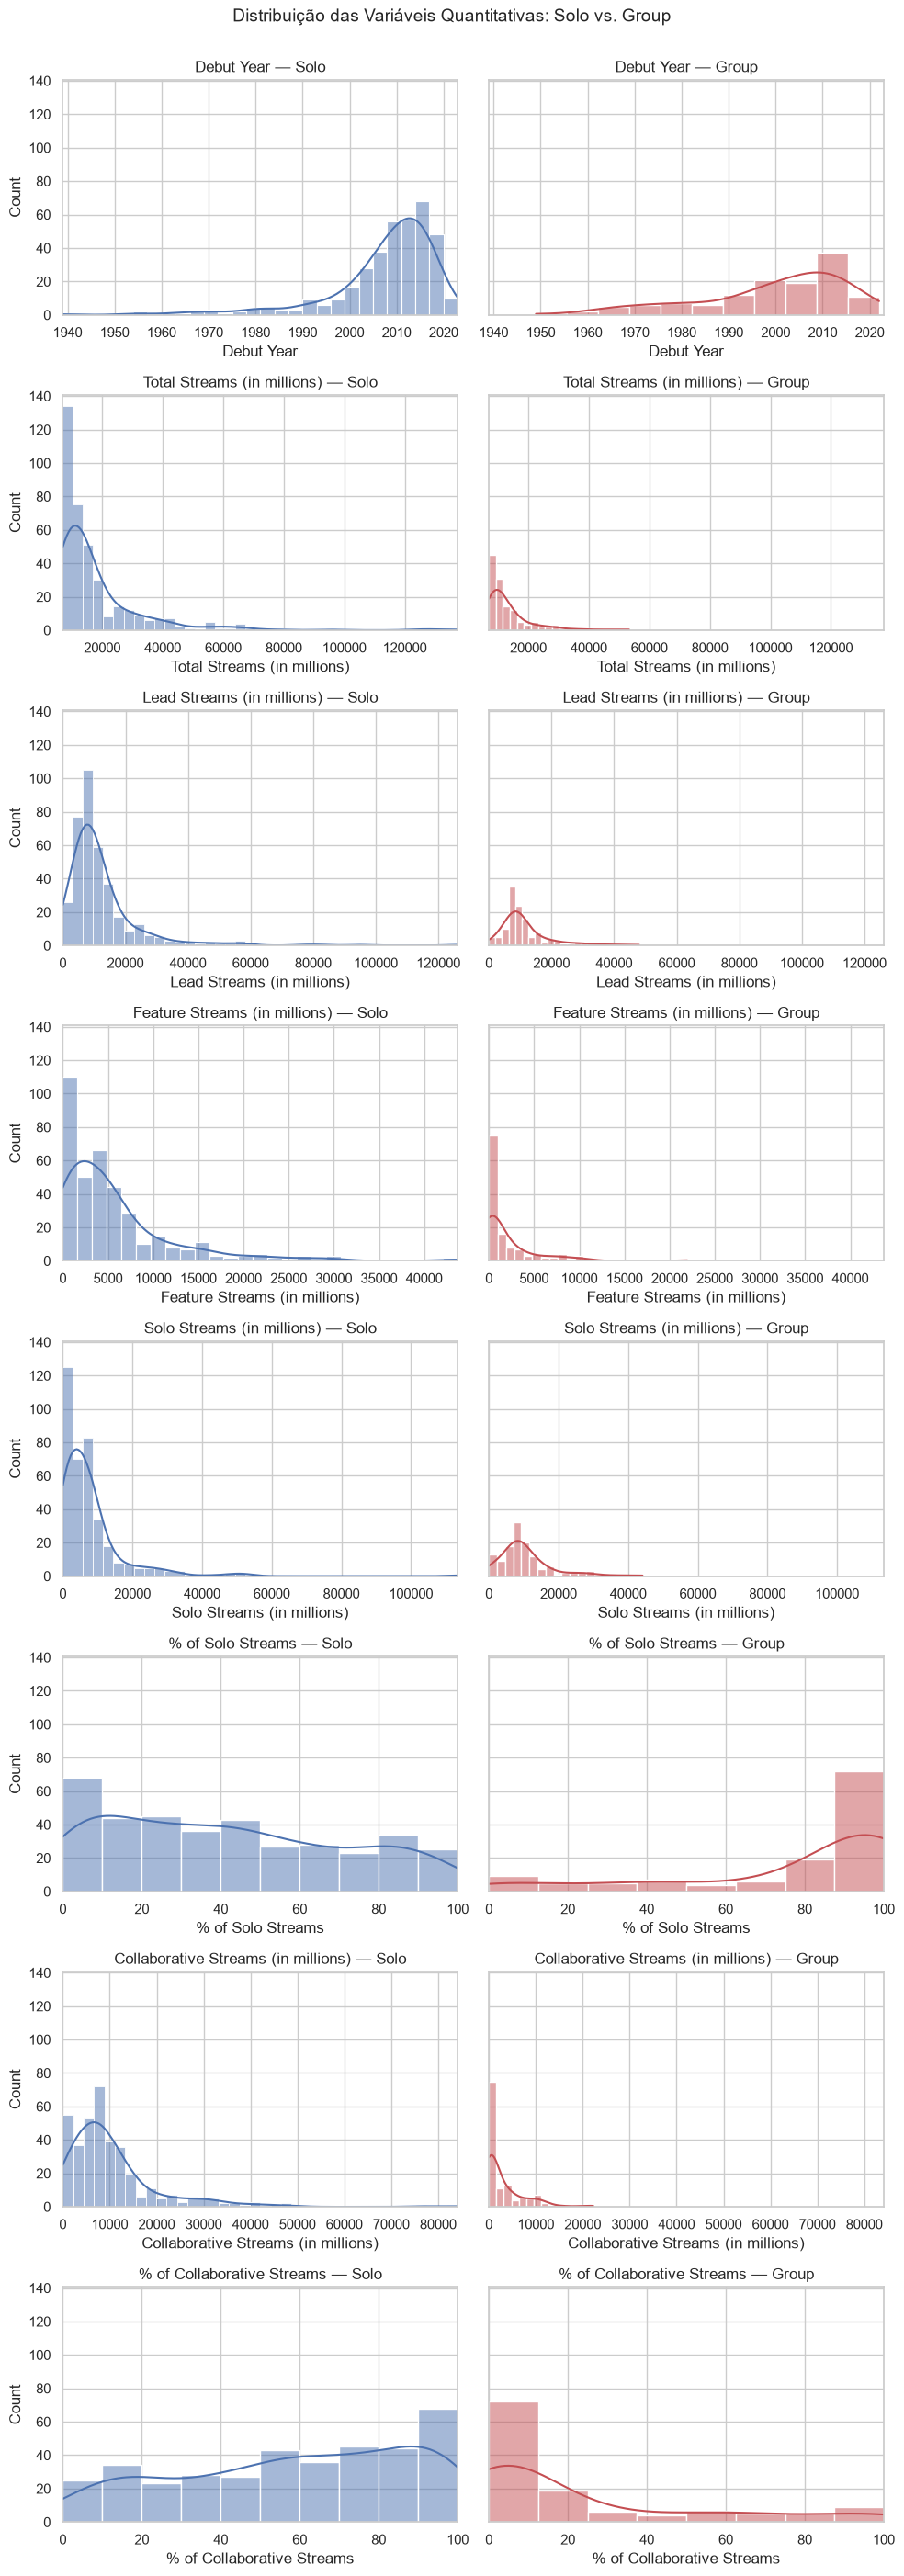

In [17]:
COR_CONTEXTO = "#4C72B0"   # cor para "Solo"
COR_DESTAQUE = "#C44E52"   # cor para "Group"

fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Solo", COR_CONTEXTO), ("Group", COR_DESTAQUE)]):
        subset = df[df["Artist Type"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Solo vs. Group", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"?

#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

Shapiro-Wilk — chol: estatística=0.5972, p-valor=1.939e-32
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


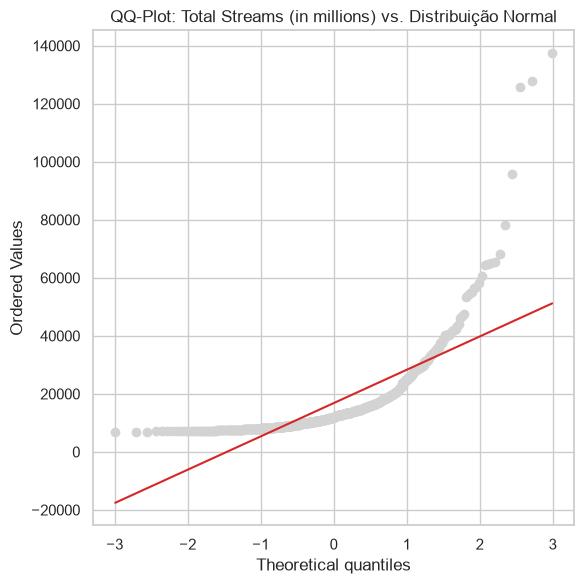

In [18]:
stat_sw, p_valor_sw = stats.shapiro(df["Total Streams (in millions)"].dropna())
print(f"Shapiro-Wilk — chol: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — colesterol"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["Total Streams (in millions)"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Total Streams (in millions) vs. Distribuição Normal")
plt.tight_layout()
plt.show()

Aqui é evidente que os dadis não seguem uma distribuição normal, principalmente nas extremidades. Deoxa evidente que poucos artsitas dominam os streamings com números muito acima da média.

Como p-valor foi menor que 0.05, deixa evidente que os dados são assimétricamente distribuídos - não normais

In [19]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

# campos de p_valor não são 0, como os dados são bem assimétricos, quanto mais a distribuição
# real se afasta da normal, menor (mais extremo) fica o p_valor do teste

# como tem mais linhas para teste (500), o teste de shapiro fica mais sensível e consegue detectar desvios de normalidade com mais facilidade

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Debut Year,0.8254,0.0,True
Total Streams (in millions),0.5972,0.0,True
Lead Streams (in millions),0.6366,0.0,True
Feature Streams (in millions),0.7315,0.0,True
Solo Streams (in millions),0.6785,0.0,True
% of Solo Streams,0.9191,0.0,True
Collaborative Streams (in millions),0.7448,0.0,True
% of Collaborative Streams,0.9191,0.0,True


**ECDF — outra forma de ver a distribuição**

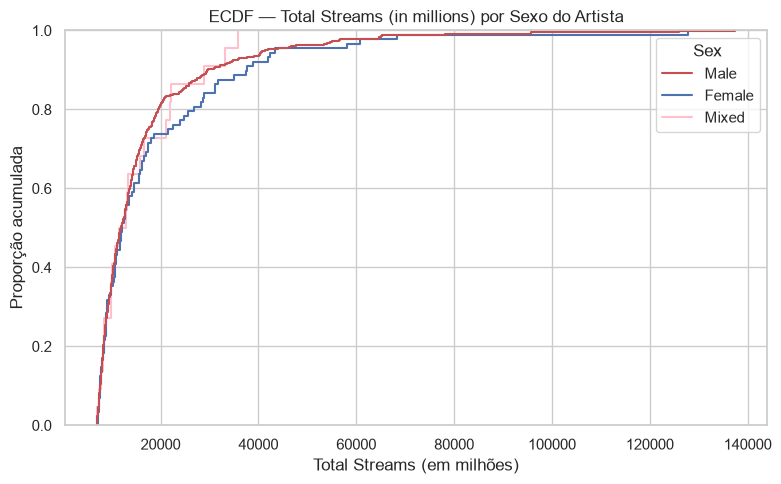

In [20]:
plt.figure(figsize=(8, 5))
COR_GRUPO = 'pink'
sns.ecdfplot(data=df, x="Total Streams (in millions)", hue="Sex",
             palette={"Female": COR_CONTEXTO, "Male": COR_DESTAQUE, "Mixed": COR_GRUPO})
plt.title("ECDF — Total Streams (in millions) por Sexo do Artista")
plt.xlabel("Total Streams (em milhões)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

A curva para artistas masculinos é maior, mas a comparação entre os grupos possui um desbalanceamento amostral (homens representam 78% do percentual total, mulheres apenas 17%, e grupos mistos apenas 4,4%), e assim, não representa de forma confiável o comportamento real da população.

Por isso a linha de mulhares e misto tem degraus mais irregulares que a de homens.

### Métricas de Tendêncial Central

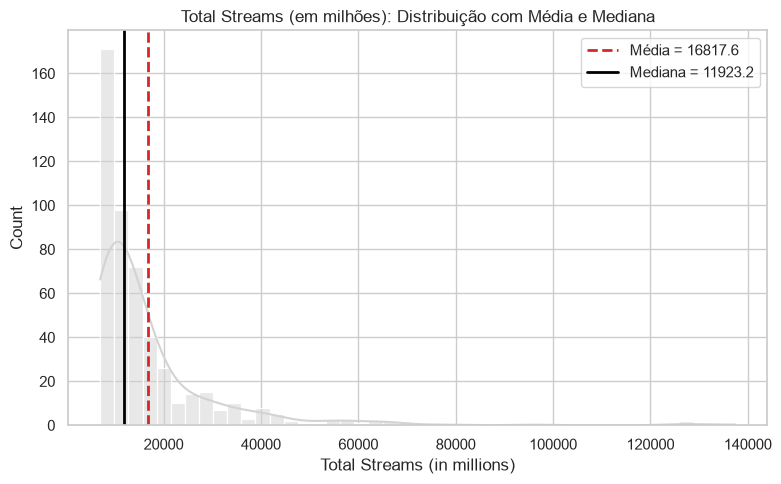

In [21]:
media_streams = df["Total Streams (in millions)"].mean()
mediana_streams = df["Total Streams (in millions)"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Total Streams (in millions)", kde=True, color=COR_NEUTRA)
plt.axvline(media_streams, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_streams:.1f}")
plt.axvline(mediana_streams, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_streams:.1f}")
plt.title("Total Streams (em milhões): Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

os poucos artistas que possuem valores extremos acabam distorcendo a média, onde a mediana representa melhor onde a maioria está de verdade.

### Dispersão

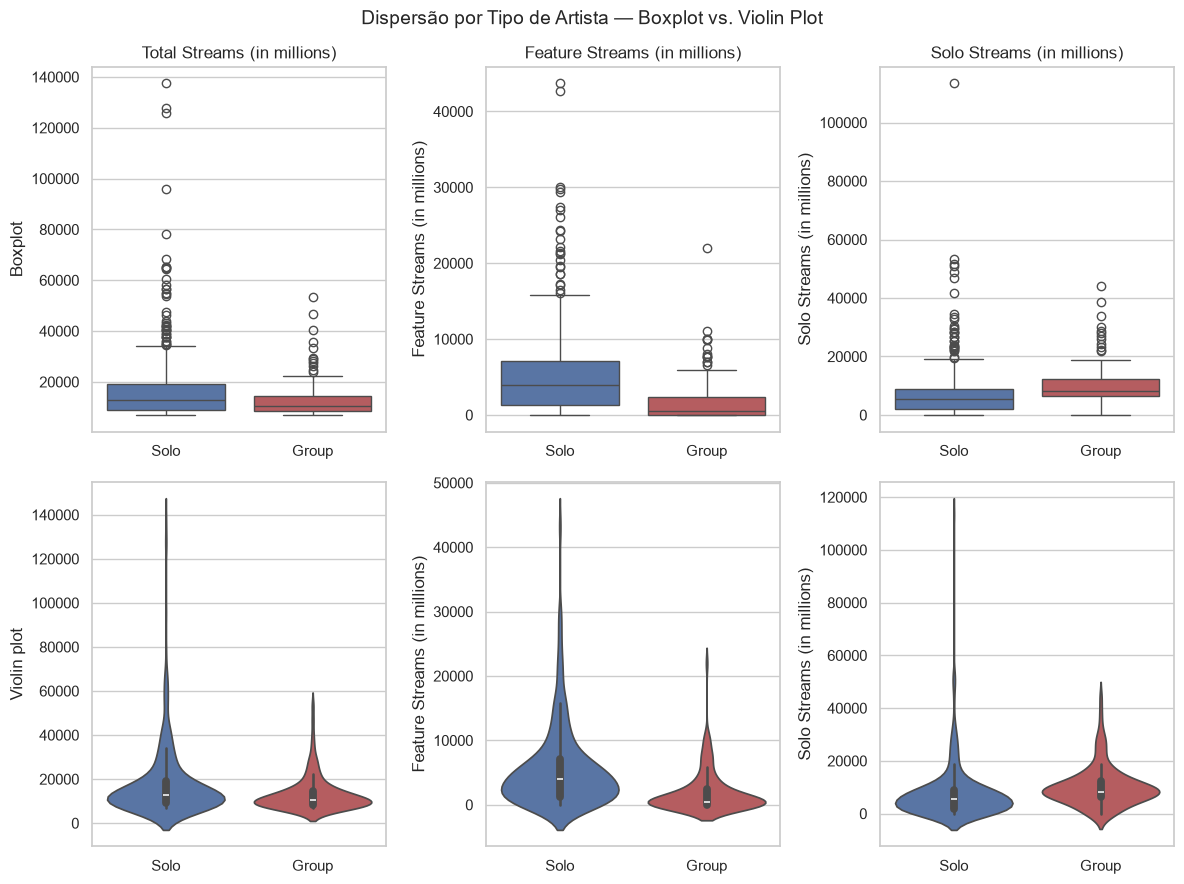

In [22]:
key_quantitative_vars = [
    "Total Streams (in millions)",
    "Feature Streams (in millions)",
    "Solo Streams (in millions)"
]

palette_artist_type = {"Solo": COR_CONTEXTO, "Group": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(key_quantitative_vars), figsize=(4 * len(key_quantitative_vars), 9), sharey=False)

for i, col in enumerate(key_quantitative_vars):
    sns.boxplot(data=df, x="Artist Type", y=col, hue="Artist Type",
                palette=palette_artist_type, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="Artist Type", y=col, hue="Artist Type",
                    palette=palette_artist_type, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Tipo de Artista — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [23]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
Debut Year,1983.38,2032.38,44.0
Total Streams (in millions),-5109.64,31897.86,49.0
Lead Streams (in millions),-3960.97,23907.62,52.0
Feature Streams (in millions),-7398.78,14188.62,36.0
Solo Streams (in millions),-8873.89,21509.21,40.0
% of Solo Streams,-74.41,177.67,0.0
Collaborative Streams (in millions),-11490.24,24525.46,32.0
% of Collaborative Streams,-77.67,174.41,0.0


### Visualizando os Outliers

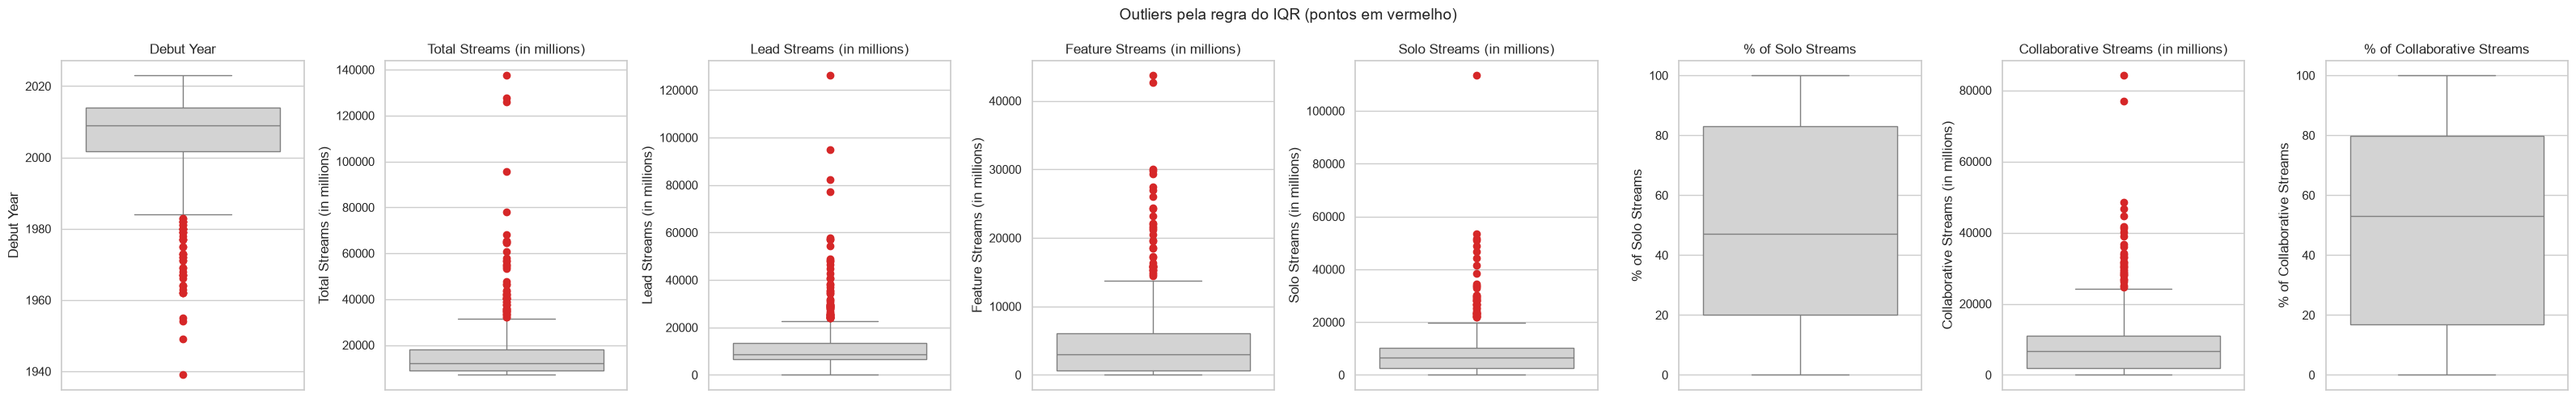

In [24]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

### Decidindo o Tratamento dos Outliers



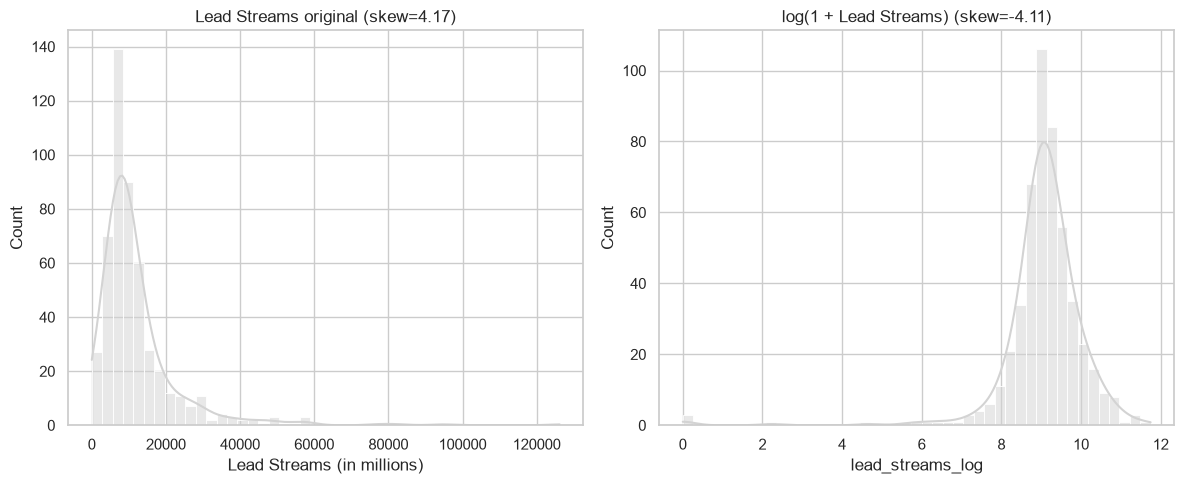

In [25]:
df["lead_streams_log"] = np.log1p(df["Lead Streams (in millions)"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="Lead Streams (in millions)", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Lead Streams original (skew={df['Lead Streams (in millions)'].skew():.2f})")

sns.histplot(data=df, x="lead_streams_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Lead Streams) (skew={df['lead_streams_log'].skew():.2f})")

plt.tight_layout()
plt.show()

A assimetria não diminuiu muito, só inverteu a direção.
 - no original, a cauda longa aparece á direita - poucos artistas com streams muito altos
 - depois, cauda longa a esquerda - a maioria dos artistas agora concentrada nos valores altos de lead_streams_log, com uma cauda esticando pra valores baixos

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [26]:
VARS_PARA_LOG = ["Total Streams (in millions)", "Lead Streams (in millions)",
                  "Feature Streams (in millions)", "Solo Streams (in millions)",
                  "Collaborative Streams (in millions)"]

VARS_QUANT_LOG = []
for col in VARS_PARA_LOG:
    nova_col = f"{col}_log"
    df[nova_col] = np.log1p(df[col])
    VARS_QUANT_LOG.append(nova_col)

as tabelas "antes" e "depois" estavam dando valores idênticos porque a segunda tabela (desc_depois) continuava usando VARS_QUANT, a lista com os nomes das colunas originais, em vez de usar as colunas transformadas. A correção foi criar de fato as colunas _log com np.log1p() para cada variável de streams e montar uma nova lista (VARS_QUANT_LOG) apontando pra essas colunas transformadas, usando ela na segunda tabela. Faz sentido criar essas colunas log porque as variáveis de streams têm forte assimetria (skew alto), então a transformação comprime os valores extremos e aproxima a distribuição de uma normal. Porém, é importante não aplicar log em todas as colunas, como "Debut Year" que é um ano (não faz sentido transformar) e as colunas de "%" já estão numa escala fixa, então filtramos só as variáveis de streams para receber a transformação.

In [27]:
desc_depois = df[VARS_QUANT_LOG].describe().T
desc_depois["skewness"] = df[VARS_QUANT_LOG].skew()
desc_depois["kurtosis"] = df[VARS_QUANT_LOG].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Total Streams (in millions)_log,9.53,9.39,0.57,8.85,11.83,1.22,1.36
Lead Streams (in millions)_log,9.06,9.07,1.09,0.00,11.75,-4.11,30.94
Feature Streams (in millions)_log,7.09,8.01,2.61,0.00,10.69,-1.55,1.65
Solo Streams (in millions)_log,8.25,8.78,1.83,0.00,11.64,-2.28,6.53
Collaborative Streams (in millions)_log,8.07,8.79,2.13,0.00,11.34,-1.95,4.07


### Comparando "antes"x "depois""



In [28]:
comparacao = pd.DataFrame({
    "skewness_antes": desc.loc[VARS_PARA_LOG, "skewness"].values,
    "skewness_depois": desc_depois.loc[VARS_QUANT_LOG, "skewness"].values,
    "kurtosis_antes": desc.loc[VARS_PARA_LOG, "kurtosis"].values,
    "kurtosis_depois": desc_depois.loc[VARS_QUANT_LOG, "kurtosis"].values,
}, index=VARS_PARA_LOG)

comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)

comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
Total Streams (in millions),3.998,1.224,22.748,1.364,-2.774,-21.383
Lead Streams (in millions),4.170,-4.110,26.708,30.943,-8.280,4.235
Feature Streams (in millions),2.607,-1.550,9.504,1.649,-4.157,-7.855
Solo Streams (in millions),4.164,-2.281,32.165,6.534,-6.445,-25.631
Collaborative Streams (in millions),2.920,-1.951,14.224,4.069,-4.870,-10.155


log melhorou a simetria de "Total Streams", "Feature Streams" e "Collaborative Streams" (skewness caiu bastante). Já "Lead Streams" não melhorou, o skewness só inverteu de sinal (4.17 e -4.11) e a kurtosis piorou, indicando que o log não foi uma boa transformação pra essa variável.

**Visualizando antes x depois, lado a lado: Efeito do Tratamento de Outliers (Capping)**

Vamos sobrepor as distribuições de duas variáveis que mais se beneficiaram do tratamento de outliers, comparando a versão original (`df`) com a tratada (`df_tratado`).

In [50]:
df_tratado = df.copy()

vars_to_compare = [
    "Total Streams (in millions)",
    "Lead Streams (in millions)"
]

for col in vars_to_compare:
    p01 = df[col].quantile(0.01)
    p99 = df[col].quantile(0.99)
    df_tratado[f"{col}_treated"] = df[col].clip(lower=p01, upper=p99)

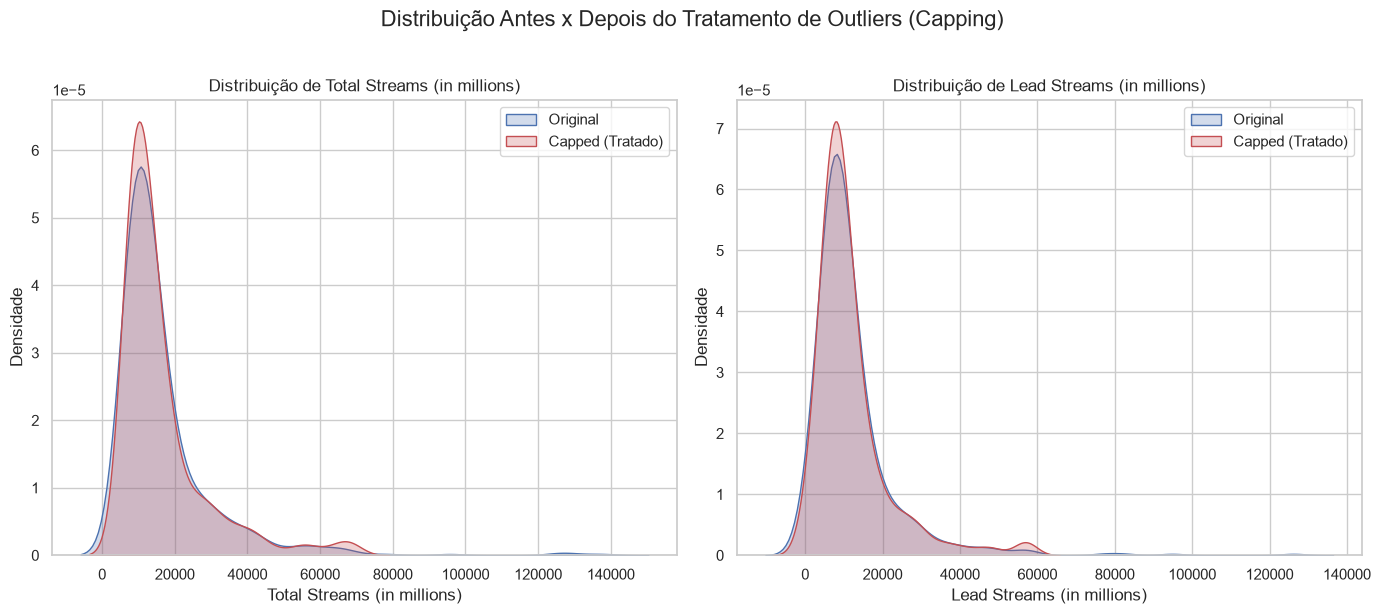

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))


for ax, col in zip(axes, vars_to_compare):
    sns.kdeplot(df[col], color=COR_CONTEXTO, fill=True, label="Original", ax=ax)
    sns.kdeplot(df_tratado[f'{col}_treated'], color=COR_DESTAQUE, fill=True, label="Capped (Tratado)", ax=ax)
    ax.set_title(f'Distribuição de {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Densidade')
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento de Outliers (Capping)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [31]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- Sex ---
        absoluta  relativa
Sex                       
Male         390     0.780
Female        88     0.176
Mixed         22     0.044
\n--- Country of Origin ---
                     absoluta  relativa
Country of Origin                      
United States             265     0.530
United Kingdom             55     0.110
Mexico                     27     0.054
Canada                     18     0.036
Colombia                   16     0.032
Brazil                     15     0.030
India                      13     0.026
South Korea                11     0.022
Argentina                   9     0.018
Australia                   7     0.014
Germany                     7     0.014
Spain                       6     0.012
Sweden                      5     0.010
France                      5     0.010
Ireland                     4     0.008
Italy                       3     0.006
Japan                       2     0.004
Scotland                    2     0.004
Jamaica                

#### Visualizando as frequências

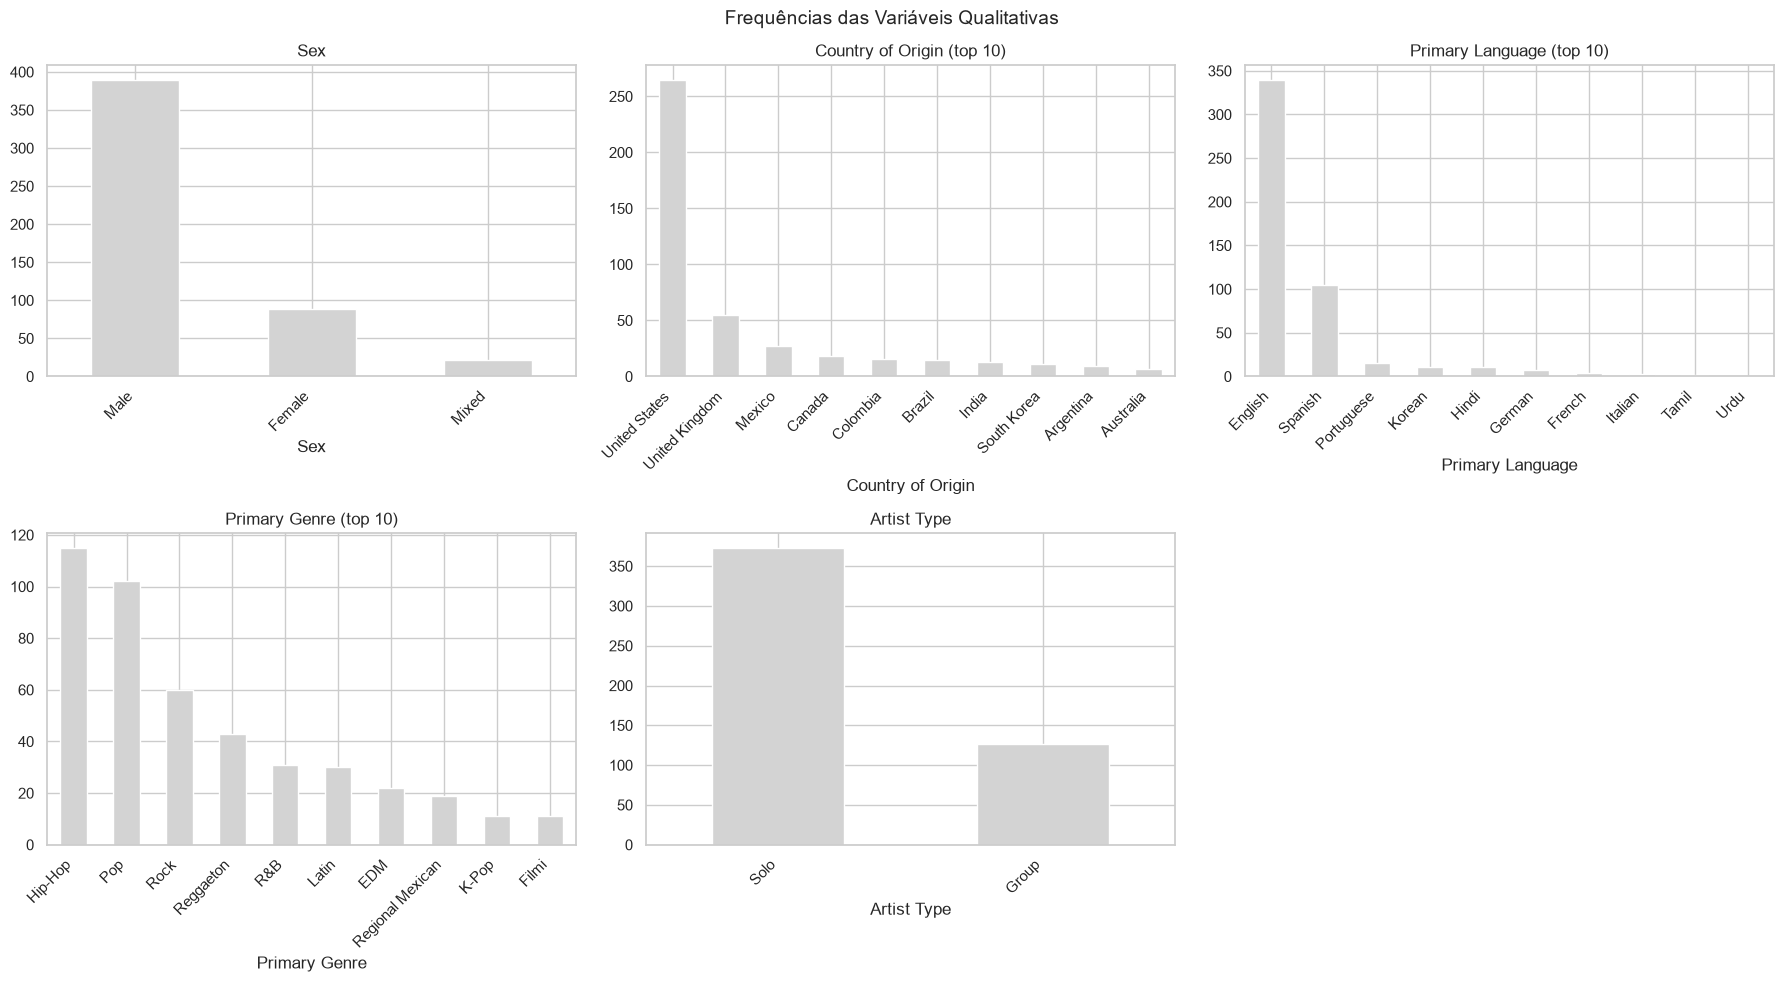

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    contagem = df[col].value_counts().sort_values(ascending=False)

    # Limitando a exibição às 10 categorias mais frequentes, se houver muitas, para evitar "aninhações"
    if len(contagem) > 10:
        contagem = contagem.head(10)
        axes[i].set_title(f"{col} (top 10)")
    else:
        axes[i].set_title(col)

    contagem.plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].tick_params(axis="x", rotation=45)
    for label in axes[i].get_xticklabels():
        label.set_ha("right")

# Removendo subplots vazios
for j in range(len(VARS_QUALI), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.


In [33]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
Sex,3.0,17.73,0.580
Country of Origin,43.0,265.00,0.548
Primary Language,11.0,340.00,0.433
Primary Genre,23.0,115.00,0.765
Artist Type,2.0,2.94,0.818


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

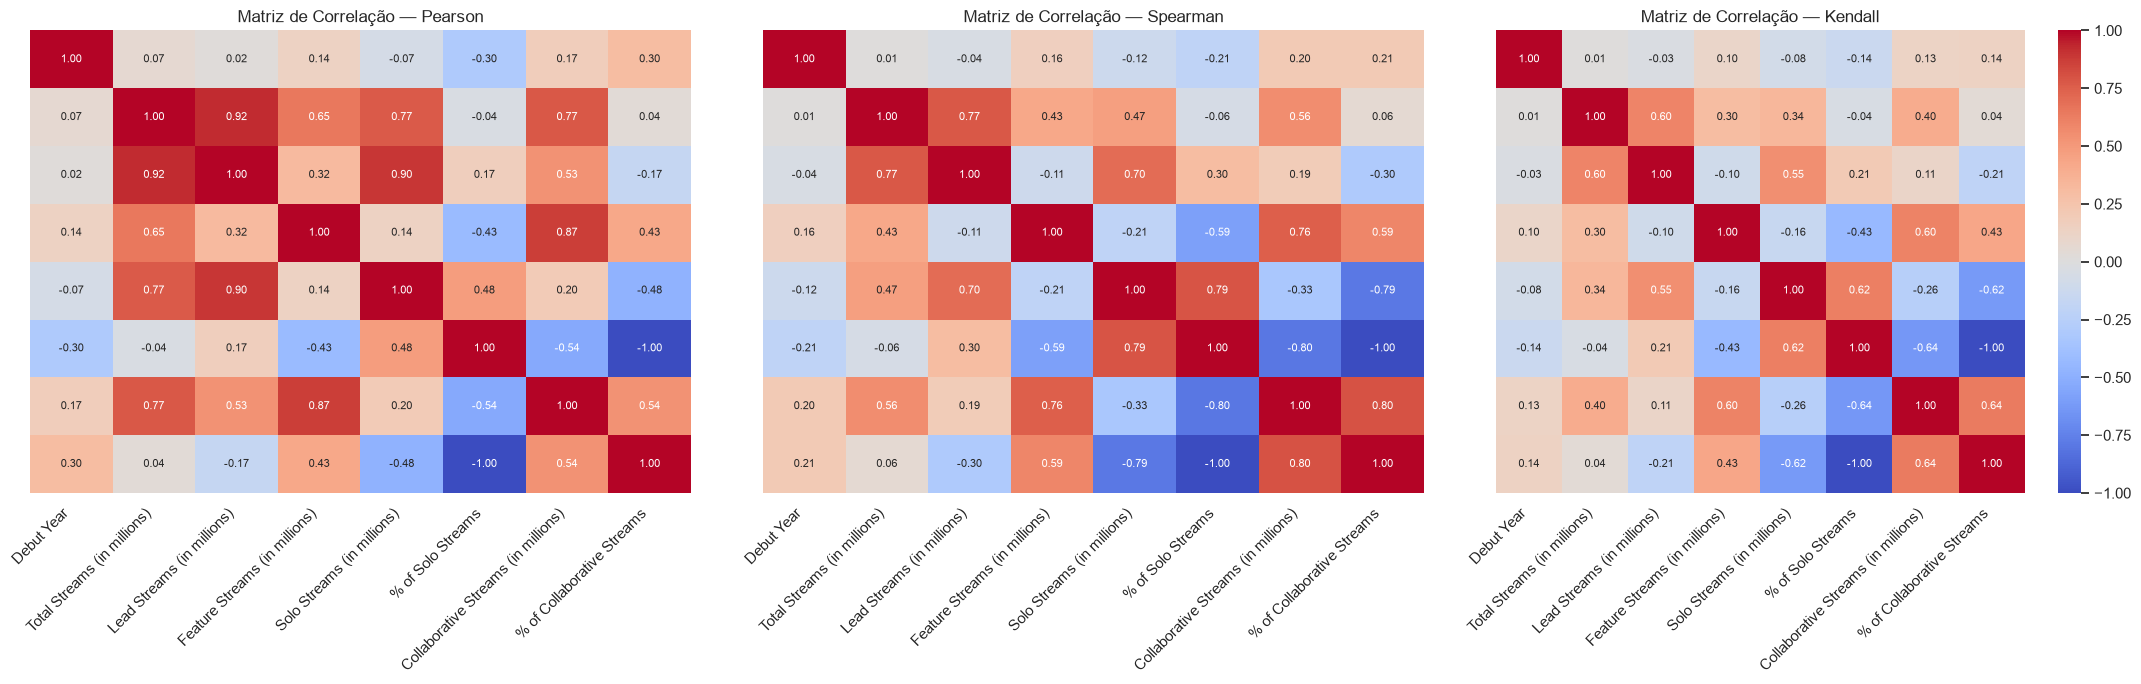

In [34]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(22, 7), sharey=True)

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            ax=ax[0], annot_kws={"size": 8}, cbar=False)
ax[0].set_title("Matriz de Correlação — Pearson")

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            ax=ax[1], annot_kws={"size": 8}, cbar=False)
ax[1].set_title("Matriz de Correlação — Spearman")

sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            ax=ax[2], annot_kws={"size": 8})
ax[2].set_title("Matriz de Correlação — Kendall")

for a in ax:
    a.set_xticklabels(a.get_xticklabels(), rotation=45, ha="right")
    a.set_yticklabels(a.get_yticklabels(), rotation=0)

plt.tight_layout()
plt.show()

Aumentei o tamanho da figura, reduzi a fonte dos números dentro das células, removi a barra de cor repetida (deixando só uma, já que as três escalas são iguais) e rotacionei os rótulos dos eixos para não ficarem cortados. Isso deixa os heatmaps mais legíveis sem alterar os dados ou o conteúdo mostrado.

é possível perceber que Streams estão fortemente correlacionados entre si (Total, Lead e Feature Streams acima de 0.90 em Pearson), o que já era esperado, pois um compõe o outro. "% of Solo" e "% of Collaborative" têm correlação perfeita negativa (-1.00), já que são complementares. "Debut Year" praticamente não se relaciona com nenhuma variável. Pearson mostra valores mais altos que Spearman em alguns pares, indicando que a relação não é totalmente linear.

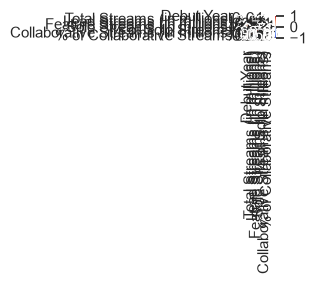

In [35]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis?
- Sim, a maior divergência é entre "Total Streams" e "Feature Streams": 0.90 no Pearson contra 0.70 no Spearman, uma diferença de 0.20. "Total Streams" e "Lead Streams" também diverge bastante (0.92 vs 0.77). Fora esses dois pares, as diferenças entre os métodos são pequenas.

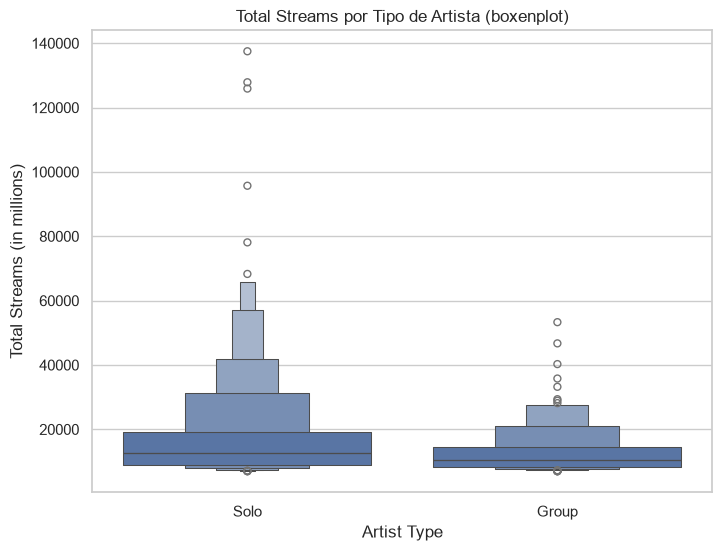

In [36]:
ANO_REFERENCIA = 2010
df["anos_carreira"] = ANO_REFERENCIA - df["Debut Year"]
df["streams_por_ano"] = df["Total Streams (in millions)"] / df["anos_carreira"]

fig, ax = plt.subplots(figsize=(8, 6))
sns.boxenplot(data=df, x="Artist Type", y="Total Streams (in millions)", ax=ax)
ax.set_title("Total Streams por Tipo de Artista (boxenplot)")
plt.show()

# Usei o boxenplot porque os dados de streams são bem desiguais, com poucos artistas puxando os números pra muito acima da maioria (como o Drake).
# um scatterplot distorcia a comparação porque havia muito mais artistas solo que em grupo, dando a impressão errada de que solo streamava mais só pela quantidade de pontos
# Um boxplot normal mostra pouca informação sobre essa "cauda longa" de valores altos, já o boxenplotmostrar diretamente a mediana e a dispersão de cada grupo,
# funcionando bem mesmo com tamanhos de amostra diferentes e captando melhor os valores extremos que puxam a distribuição.

é possível observar algumas coisas:
- o boxenplot mostra que artistas solo têm uma mediana de streams um pouco maior que os artistas em grupo
- os artistas solo apresentam uma dispersão muito maior, com as camadas do gráfico se alargando de forma bem mais acentuada à medida que sobem, e outliers extremos (137 milhões de streams)
- os artistas em grupo formam uma distribuição bem mais compacta e homogênea, com a maioria concentrada numa faixa mais estreita e o outlier mais alto bem menor que o do grupo solo

#### Quantitativa x Qualitativa: Comparando Grupos


In [37]:
resultados_comparacao = []
for col in VARS_QUANT:
    # Comparando 'Solo' e 'Group' do 'Artist Type'
    grupo_solo = df.loc[df["Artist Type"] == "Solo", col]
    grupo_group = df.loc[df["Artist Type"] == "Group", col]

    # Garantir que ambos os grupos tenham dados para comparação
    if not grupo_solo.empty and not grupo_group.empty:
        stat_t, p_t = stats.ttest_ind(grupo_solo, grupo_group, equal_var=False)
        stat_u, p_u = stats.mannwhitneyu(grupo_solo, grupo_group)

        resultados_comparacao.append({
            "variavel": col,
            "p_valor_ttest": round(p_t, 5),
            "p_valor_mannwhitney": round(p_u, 5),
            "concordam": (p_t < 0.05) == (p_u < 0.05),
        })
    else:
        resultados_comparacao.append({
            "variavel": col,
            "p_valor_ttest": np.nan,
            "p_valor_mannwhitney": np.nan,
            "concordam": False,
            "observacao": "Um ou ambos os grupos (Solo/Group) estão vazios para esta variável."
        })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
Debut Year,0.00000,0.00000,True
Total Streams (in millions),0.00002,0.00154,True
Lead Streams (in millions),0.29144,0.48412,True
Feature Streams (in millions),0.00000,0.00000,True
Solo Streams (in millions),0.00210,0.00000,True
% of Solo Streams,0.00000,0.00000,True
Collaborative Streams (in millions),0.00000,0.00000,True
% of Collaborative Streams,0.00000,0.00000,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)?
- Sim, os dois testes são True em todas as variáveis. Em 6 delas ambos os testes são significativos (p < 0.05). Só em Lead Streams ambos concordam em não ser significativo (p > 0.05 nos dois).

ANOVA          — Total Streams (in millions) entre categorias de Primary Language: estatística=1.143, p-valor=0.33569
Kruskal-Wallis — Total Streams (in millions) entre categorias de Primary Language: estatística=9.314, p-valor=0.053703


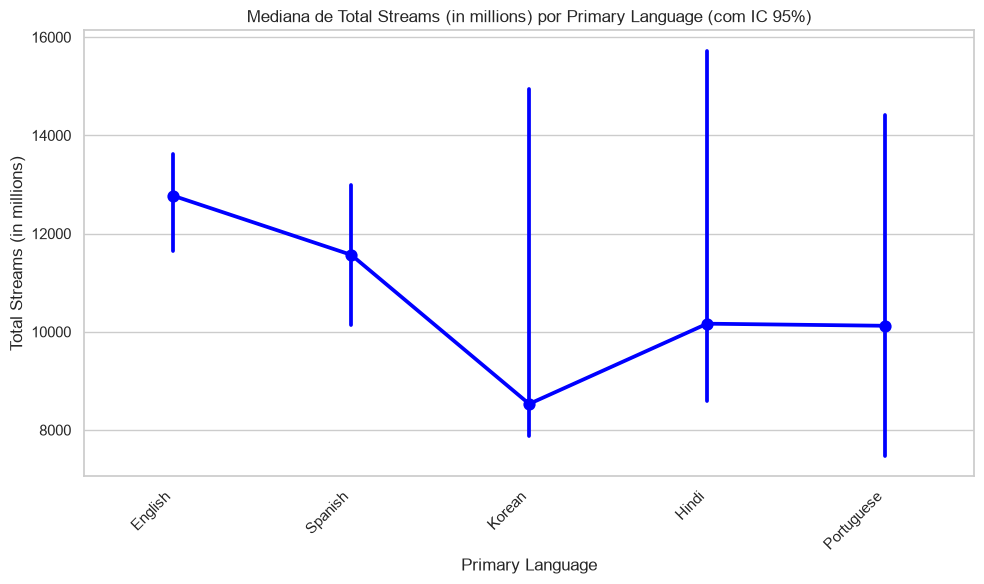

In [38]:
col_qualitativa = "Primary Language"
col_quantitativa = "Total Streams (in millions)"

# Filtrando idiomas com pelo menos 10 artistas para testes e visualização
min_artists_per_group = 10
valid_languages = df[col_qualitativa].value_counts()
valid_languages = valid_languages[valid_languages >= min_artists_per_group].index.tolist()

df_filtered = df[df[col_qualitativa].isin(valid_languages)]

if len(valid_languages) >= 2:
    grupos = [grupo[col_quantitativa].values for _, grupo in df_filtered.groupby(col_qualitativa)]

    stat_anova, p_anova = stats.f_oneway(*grupos)
    stat_kw, p_kw = stats.kruskal(*grupos)

    print(f"ANOVA          — {col_quantitativa} entre categorias de {col_qualitativa}: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
    print(f"Kruskal-Wallis — {col_quantitativa} entre categorias de {col_qualitativa}: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

    plt.figure(figsize=(10, 6))
    sns.pointplot(
    data=df_filtered,
    x=col_qualitativa,
    y=col_quantitativa,
    estimator="median",
    errorbar=("ci", 95),
    color="blue"
    )
    plt.title(f"Mediana de {col_quantitativa} por {col_qualitativa} (com IC 95%)")
    plt.xlabel(col_qualitativa)
    plt.ylabel(col_quantitativa)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print(f"Não há grupos suficientes em '{col_qualitativa}' com pelo menos {min_artists_per_group} artistas para realizar a comparação estatística.")

Usei o pointplot porque acho que demonstra melhor se a diferença entre eles é confiável de verdade, que foi o que os testes ANOVA e Kruskal-Wallis avaliaram. O boxplot mostra bem a forma de cada grupo, mas não deixa claro o quanto dá pra confiar naquela mediana. Já o pointplot com intervalo de confiança resolve, quando as barras de erro de dois idiomas se cruzam, como aconteceu com quase todos aqui, isso já é um sinal visual de que a diferença pode não ser real, só coincidência da amostra.

#### Quantitativa x Qualitativa

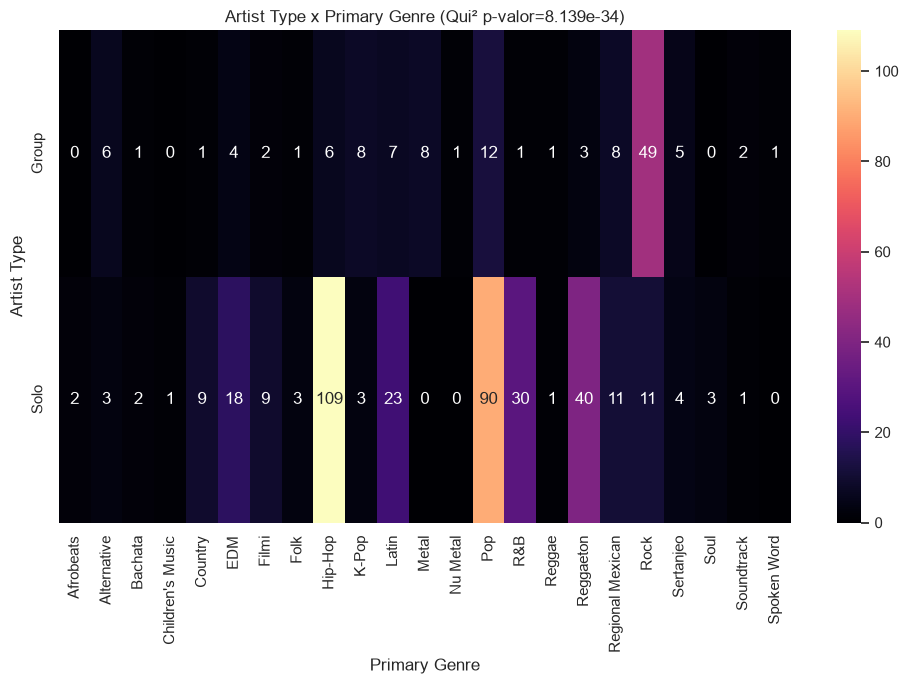

In [39]:
col_quali_1 = "Artist Type"
col_quali_2 = "Primary Genre"

contingencia = pd.crosstab(df[col_quali_1], df[col_quali_2])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia)

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"{col_quali_1} x {col_quali_2} (Qui² p-valor={p_chi2:.4g})")
plt.xlabel(col_quali_2)
plt.ylabel(col_quali_1)
plt.tight_layout()
plt.show()

#### Avaliação de Fairness


In [40]:
df["faixa_de_estreia"] = pd.cut(df["Debut Year"], bins=[1930, 2000, 2010, 2024],
                             labels=["Antes de 2000", "2000-2009", "2010-Presente"])

print("Desbalanceamento — Sexo:")
print(metrica_desbalanceamento(df["Sex"]))
print("\nDesbalanceamento — Faixa de Estreia:")
print(metrica_desbalanceamento(df["faixa_de_estreia"]))

Desbalanceamento — Sexo:
n_classes                  3.00
razao_desbalanceamento    17.73
entropia_normalizada       0.58
dtype: float64

Desbalanceamento — Faixa de Estreia:
n_classes                 3.000
razao_desbalanceamento    1.880
entropia_normalizada      0.971
dtype: float64


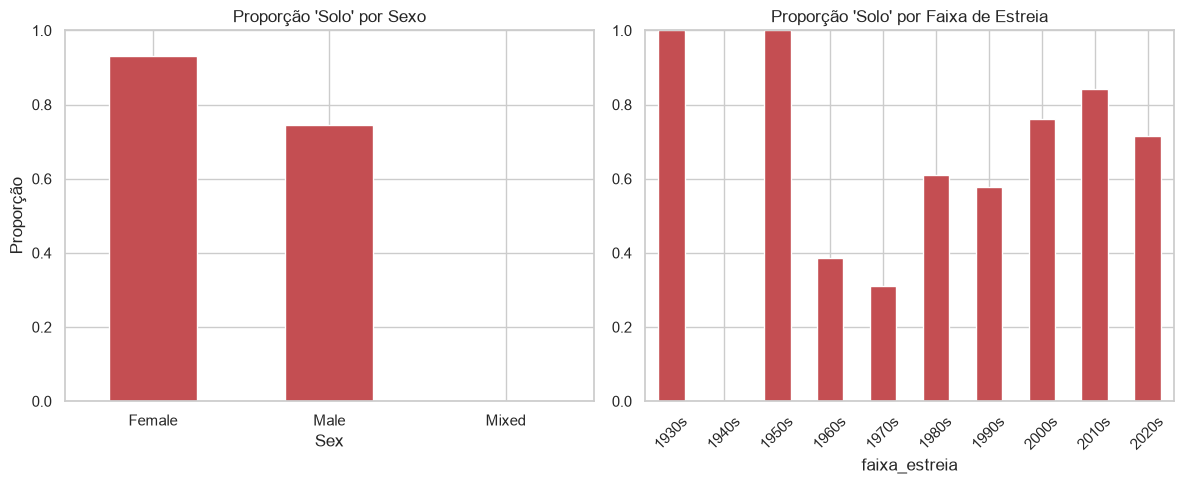

In [41]:
# Criando faixa de estreia por década =
df["faixa_estreia"] = (df["Debut Year"] // 10 * 10).astype(str) + "s"

prop_por_sexo = pd.crosstab(df["Sex"], df["Artist Type"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_estreia"], df["Artist Type"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_sexo["Solo"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Solo' por Sexo")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa["Solo"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Solo' por Faixa de Estreia")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

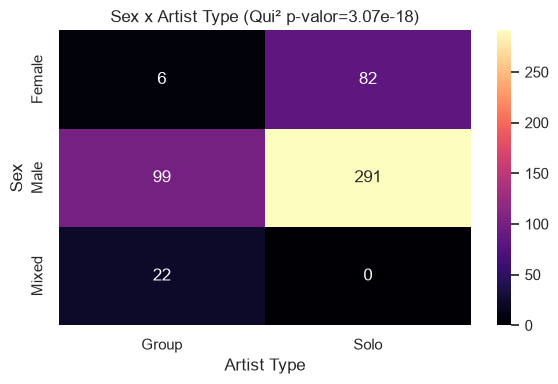

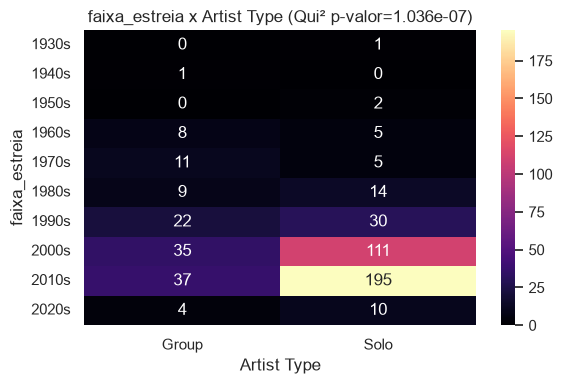

In [42]:
for atributo in ["Sex", "faixa_estreia"]:
    contingencia = pd.crosstab(df[atributo], df["Artist Type"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x Artist Type (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

#### Outliers bivariados

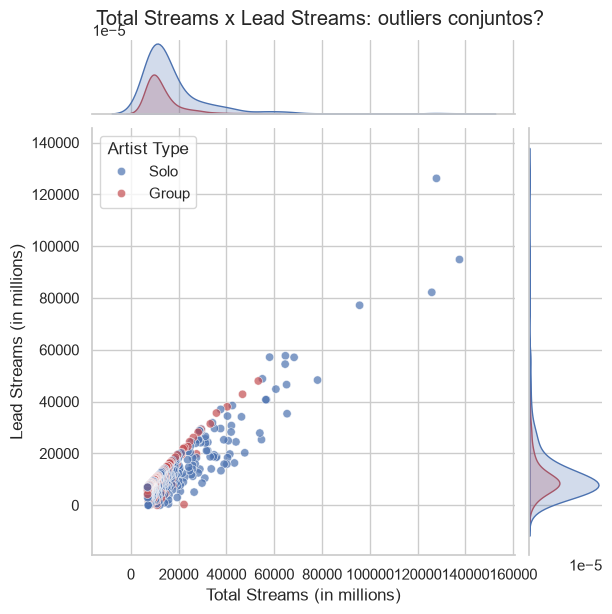

In [43]:
sns.jointplot(data=df, x="Total Streams (in millions)", y="Lead Streams (in millions)", hue="Artist Type",
              palette={"Solo": COR_CONTEXTO, "Group": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Total Streams x Lead Streams: outliers conjuntos?", y=1.02)
plt.show()

é evidente que Um artista do grupo "Group" com cerca de 45.000 Total Streams e 48.000 Lead Streams se destaca, pois tem uma proporção de lead muito maior que o normal para artistas em grupo, mesmo esses valores não sendo extremos sozinhos. Também há um ponto "Solo" perto de 80.000 Total Streams com Lead Streams de só 48.000, abaixo do esperado para artistas solo com esse total, mostrando uma combinação incomum mesmo sem outlier em cada variável isolada.

#### Análise Multivariada

##### Matriz de Correlação

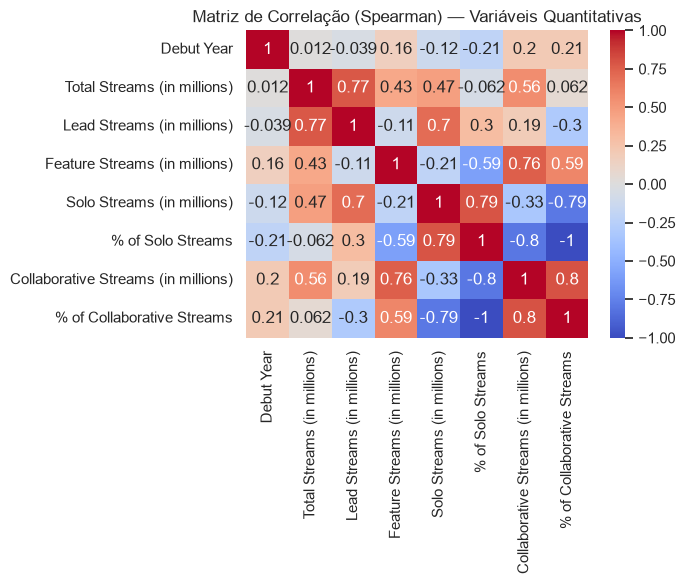

In [44]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?
- Sim. "% of Solo Streams" e "% of Collaborative Streams" têm correlação -1. "Total Streams" e "Lead Streams" (0.77), "Feature Streams" e "Solo Streams" (0.70), "Collaborative Streams" e "Feature Streams" (0.76), e "% of Solo Streams" com "Collaborative Streams"/"% of Collaborative Streams" (-0.8 e -0.79) também são fortes, visto que essas variáveis são partes que compõem o total. Isso indica que não faz sentido usar todas juntas em um modelo, por exemplo, já que possuem informação redundante.

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

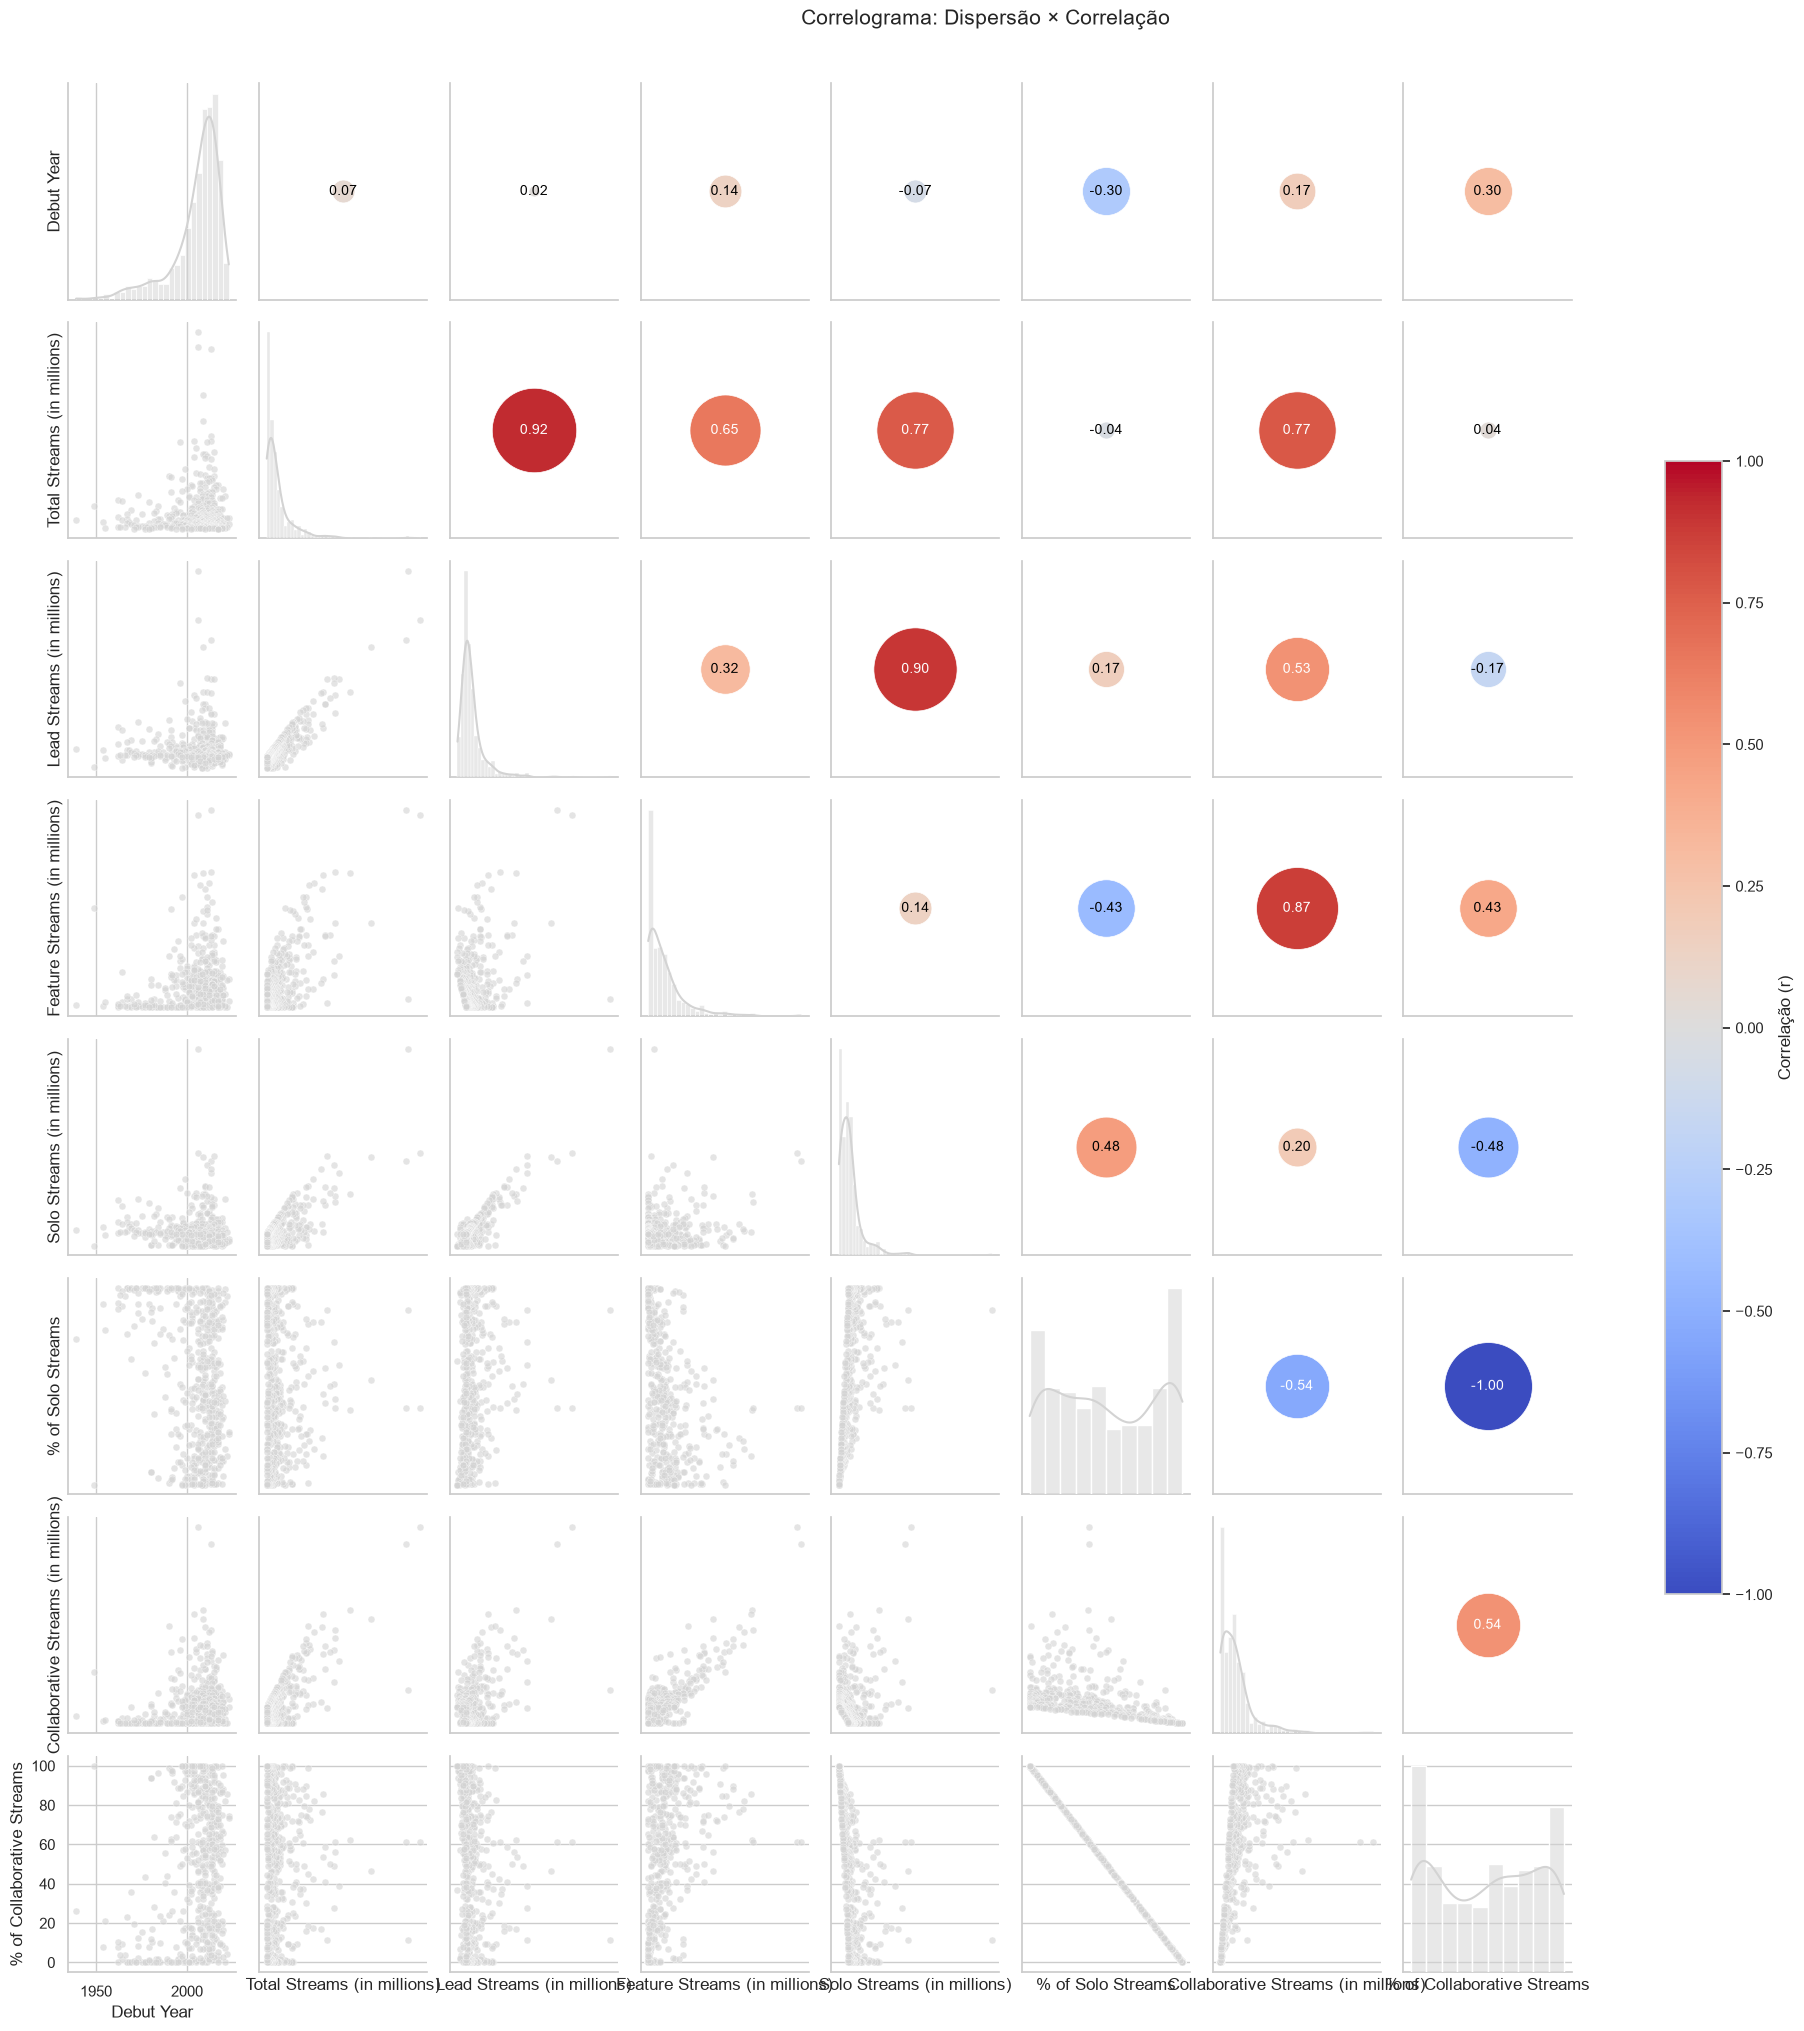

In [45]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)

** gráfico extremamente grande :(

### Declaração do uso de IA:
- **ferramentas utilizadas**: Claude e Gemini do próprio notebookLM
- **Aplicação**: Me auxiliar a idêntificar que ajustes deveria fazer nos códigos que poderiam ser reaproveitados para o meu dataset e identificar erros de biibliotecas que não tinha conhecimento prévio, como: scipy.stats, matplotlib.cm e outros
- **o que foi aceito/modificado**: pequenos ajustes de layout que eu estava com dificuldades para resolver, e pequenas substituições como os nomes das colunas do antigo dataset para o meu dataset, ajuda nas perguntas e sugestões de substituição de gráficos

In [46]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [48]:
# Salvar o dataset original do Spotify
df_raw = pd.read_csv(caminho_csv, sep=",")

PASTA_RAW.mkdir(parents=True, exist_ok=True)
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(
    f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — "
    f"{df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas"
)

Raw salvo em ..\data\raw\dataset.csv — 500 linhas x 14 colunas


In [49]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")

Clean salvo em ..\data\clean\dataset.csv — 500 linhas x 24 colunas
Linhas removidas no tratamento: 0
